## PC1: Profile Every File Before You Clean It
Checks the shape, data types, blanks, duplicates, and label variants of all seven raw files before any change.

In [1]:
import pandas as pd

names = [
    "customers", "products", "orders", "order_items",
    "payments", "shipments", "returns"
]

data = {
    n: pd.read_csv(f"../data/raw/{n}.csv") for n in names
}

for n, df in data.items():
    print(n, df.shape, "| duplicates:", df.duplicated().sum())
    missing = df.isna().sum()
    print(missing[missing > 0], "\n")

customers (5050, 13) | duplicates: 50
gender          301
age             150
email           107
phone           147
loyalty_tier    266
dtype: int64 

products (800, 9) | duplicates: 0
stock_qty    19
dtype: int64 

orders (15075, 8) | duplicates: 75
discount_pct    758
shipping_fee    474
dtype: int64 

order_items (37763, 5) | duplicates: 262
unit_price_at_purchase    2262
dtype: int64 

payments (15000, 6) | duplicates: 0
amount_paid    878
dtype: int64 

shipments (15000, 7) | duplicates: 0
delivered_date    729
dtype: int64 

returns (1200, 6) | duplicates: 0
refunded_flag    110
refund_amount    187
dtype: int64 



## PC2: Create Working Copies and the Cleaning Log
Makes working copies of the raw files and starts the cleaning log that records every fix.

In [2]:
clean = {
    n: df.copy() for n, df in data.items()
}

cleaning_log = []

def log_fix(code, table, issue, action, before, after, reason, verified_by):
    cleaning_log.append({
        "Code": code,
        "Table": table,
        "Issue": issue,
        "Action": action,
        "Rows before": before,
        "Rows after": after,
        "Reason": reason,
        "Verified by": verified_by
    })

## PC3: Remove Exact Duplicates
Removes rows where every column is identical and logs the rows removed from each table.

In [3]:
for n in ["customers", "orders", "order_items"]:
    before = len(clean[n])
    clean[n] = clean[n].drop_duplicates()
    after = len(clean[n])
    log_fix(
        "PC3",
        n,
        f"{before - after} exact duplicate rows",
        "drop_duplicates()",
        before,
        after,
        "Exact duplicates can silently inflate counts and revenue",
        f"duplicated().sum() = {clean[n].duplicated().sum()}"
    )

for n, key in [
    ("customers", "customer_id"),
    ("orders", "order_id"),
    ("order_items", "order_item_id")
]:
    print(n , key, "| repeated IDs:", clean[n].duplicated(subset=[key]).sum())

pd.DataFrame(cleaning_log)

customers customer_id | repeated IDs: 0
orders order_id | repeated IDs: 0
order_items order_item_id | repeated IDs: 0


,Code,Table,Issue,Action,Rows before,Rows after,Reason,Verified by
0,PC3,customers,50 exact duplicate rows,drop_duplicates(),5050,5000,Exact duplicates can silently inflate counts a...,duplicated().sum() = 0
1,PC3,orders,75 exact duplicate rows,drop_duplicates(),15075,15000,Exact duplicates can silently inflate counts a...,duplicated().sum() = 0
2,PC3,order_items,262 exact duplicate rows,drop_duplicates(),37763,37501,Exact duplicates can silently inflate counts a...,duplicated().sum() = 0


## PC4: Convert Currency Text to Numbers
Converts money values stored as text with ₱ signs and commas into numbers.

In [4]:
def clean_currency(series):
    return pd.to_numeric(
        series.astype("string")
            .str.replace("₱", "", regex = False)
            .str.replace(",", "", regex = False)
            .str.strip(),
        errors = "coerce",
    ).astype("float64")


money_cols = [
    ("products", "unit_price"),
    ("order_items", "unit_price_at_purchase"),
    ("payments", "amount_paid")
]


for n, col in money_cols:
    df = clean[n]
    text_values = df[col].astype("string").str.contains("₱|,", na = False).sum()
    missing_before = df[col].isna().sum()
    df[col] = clean_currency(df[col])
    missing_after = df[col].isna().sum()

    print(
        f"{n}.{col}: {text_values} text values fixed | dtype: {df[col].dtype}"
        f" | missing before / after: {missing_before}/{missing_after}"
    )

    log_fix(
        "PC4",
        n,
        f"{col}: {text_values} values stored as text (₱ sign or commas)",
        "clean_currency(): remove ₱ and commas, then pd.to_numeric(errors = 'coerce')",
        len(df),
        len(df),
        "Numbers stored as text cannot be summed, averaged, or compared",
        f"dtype = {df[col].dtype}; missing before = {missing_before}, after = {missing_after}"
    )

products.unit_price: 68 text values fixed | dtype: float64 | missing before / after: 0/0
order_items.unit_price_at_purchase: 3017 text values fixed | dtype: float64 | missing before / after: 2236/2236
payments.amount_paid: 556 text values fixed | dtype: float64 | missing before / after: 878/878


## PC5: Standardize Category and Gender Labels
Maps category aliases to 8 standard categories and gender variants to Male, Female, and Unknown.

In [5]:
gender_map = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female",
    "unknown": "Unknown"
}

category_map = {
    "book": "books",
    "elec": "electronics",
    "toy": "toys",
    "grocery": "groceries",
    "fashon": "fashion",
    "home and kitchen": "home & kitchen",
    "beauty & care": "beauty",
    "sports & outdoor": "sports"
}

for n, col, mapping in [("customers", "gender", gender_map),
                        ("products", "category", category_map)]:
    df = clean[n]
    labels_before = df[col].nunique()
    df[col] = (
        df[col].astype("string")
            .str.strip()
            .str.lower()
            .replace(mapping)
            .str.title()
    )
    labels_after = df[col].nunique()

    print(f"{n}.{col}: {labels_before} labels -> {labels_after}")
    print(df[col].value_counts(dropna = False).to_string(), "\n")

    log_fix(
        "PC5",
        n,
        f"{col}: {labels_before} spellings for {labels_after} values",
        "strip(), lower(), map aliases and typos, then title()",
        len(df),
        len(df),
        "Spelling variants split one group into several in groupby()",
        f"nunique() before = {labels_before}, after = {labels_after}"
    )

customers.gender: 6 labels -> 3
gender
Female     2099
Male       2016
Unknown     587
<NA>        298 

products.category: 18 labels -> 8
category
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82 



## PC6: Parse Mixed Date Formats
Parses the mixed date formats in every date column and confirms that no date failed to parse.

In [6]:
date_cols = [
    ("orders", "order_datetime"),
    ("payments", "payment_date"),
    ("shipments", "ship_date"),
    ("shipments", "delivered_date"),
    ("returns", "return_request_date"),
    ("customers", "signup_date"),
    ("products", "launch_date")
]

for n, col in date_cols:
    df = clean[n]
    text = df[col].dropna().astype("string")
    slash = text[text.str.match(r"\d{2}/\d{2}/\d{4}")]
    first_over_12 = (slash.str[:2].astype(int) > 12).sum()
    second_over_12 = (slash.str[3:5].astype(int) > 12).sum()

    missing_before = df[col].isna().sum()
    df[col] = pd.to_datetime(df[col], format = "mixed", errors = "coerce")
    failed = df[col].isna().sum() - missing_before

    print(
        f"{n}.{col}: {len(slash)} slash dates (first part > 12: {first_over_12}, "
        f"second part > 12: {second_over_12}) | failed: {failed} | "
        f"{df[col].min():%Y-%m-%d} to {df[col].max():%Y-%m-%d}"
    )

    log_fix(
        "PC6",
        n,
        f"{col}: mixed date formats stored as text",
        "pd.to_datetime(format = 'mixed', errors = 'coerce'), month first",
        len(df),
        len(df),
        "Text dates cannot be sorted, filtered by month, or subtracted",
        f"failed to parse = {failed}; slash dates with first part > 12 = {first_over_12}, "
        f"second part > 12 = {second_over_12}, so they are month first"
    )

orders.order_datetime: 1807 slash dates (first part > 12: 0, second part > 12: 1071) | failed: 0 | 2024-01-01 to 2026-01-31
payments.payment_date: 2260 slash dates (first part > 12: 0, second part > 12: 1376) | failed: 0 | 2024-01-01 to 2026-01-31
shipments.ship_date: 0 slash dates (first part > 12: 0, second part > 12: 0) | failed: 0 | 2024-01-01 to 2026-01-31
shipments.delivered_date: 2173 slash dates (first part > 12: 0, second part > 12: 1326) | failed: 0 | 2024-01-02 to 2026-02-07
returns.return_request_date: 231 slash dates (first part > 12: 0, second part > 12: 140) | failed: 0 | 2024-01-01 to 2026-01-29
customers.signup_date: 654 slash dates (first part > 12: 0, second part > 12: 402) | failed: 0 | 2023-01-01 to 2026-01-31
products.launch_date: 69 slash dates (first part > 12: 0, second part > 12: 31) | failed: 0 | 2022-01-03 to 2024-09-26


## PC7: Handle Missing Values
Fills blank labels with "Unknown" and backfills blank purchase prices from the product list price.

In [7]:
# A) Text fields: keep the row and give the blank its own label
for n, col, label in [
                    ("customers", "gender", "Unknown"),
                    ("customers", "loyalty_tier", "Unknown"),   
                    ("returns", "refunded_flag", "Unknown")]:
    df = clean[n]
    filled = df[col].isna().sum()
    df[col] = df[col].fillna(label)
    print(f"{n}.{col}: {filled} blanks -> '{label}'")
    log_fix(
        "PC7",
        n,
        f"{col}: {filled} missing values",
        f"fillna('{label}')",
        len(df),
        len(df),
        "Keeps the row and shows the blank as its own group",
        f"isna().sum() = {df[col].isna().sum()}"
    )

# B) Purchase price: backfill from the product's list price, then flag it
items = clean["order_items"]
list_price = items["product_id"].map(clean["products"].set_index("product_id")["unit_price"])
both = items["unit_price_at_purchase"].notna() & list_price.notna()
same = (items.loc[both, "unit_price_at_purchase"] == list_price[both]).mean()
items["price_was_backfilled"] = items["unit_price_at_purchase"].isna() & list_price.notna()
items["unit_price_at_purchase"] = items["unit_price_at_purchase"].fillna(list_price)
backfilled = items["price_was_backfilled"].sum()
still_missing = items["unit_price_at_purchase"].isna().sum()

print(f"\norder_items.unit_price_at_purchase: equals list price in {same:.0%} of "
        f"{both.sum()} rows with both prices")
print(f" backfilled: {backfilled} | still missing (product not in products.csv): {still_missing}")

log_fix(
    "PC7",
    "order_items",
    f"unit_price_at_purchase: {backfilled + still_missing} missing values",
    "Backfill from products.unit_price; new flag column price_was_backfilled",
    len(items),
    len(items),
    "Purchase price equals list price in every row that has both",
    f"match rate = {same:.0%}; backfilled = {backfilled}; still missing = {still_missing}"
)

# C) Keep blank: no safe fill value, and isna() keeps the blank visible
zero_share = (clean["orders"]["discount_pct"] == 0).sum() / clean["orders"]["discount_pct"].notna().sum()
print(f"\norders.discount_pct: only {zero_share:.0%} of recorded discounts are 0\n")

keep_blank = {
    ("customers", "age"): "A guessed age would distort age groups",
    ("customers", "email"): "Contact fields are not used in the analysis",
    ("customers", "phone"): "Contact fields are not used in the analysis",
    ("products", "stock_qty"): "A stock level cannot be guessed",
    ("orders", "discount_pct"): "Most recorded discounts are above 0. A blank cannot be assumed to be 0",
    ("orders", "shipping_fee"): "A guessed fee would distort fee totals",
    ("payments", "amount_paid"): "A guessed amount would distort payment totals",
    ("shipments", "delivered_date"): "A blank can mean the parcel is not delivered yet",
    ("returns", "refund_amount"): "Checked against refunded_flag in PC8"
}
for (n, col), reason in keep_blank.items():
    missing = clean[n][col].isna().sum()
    print(f"{n}.{col}: {missing} kept blank")
    log_fix(
        "PC7",
        n,
        f"{col}: {missing} missing values",
        "Kept blank (no fill)",
        len(clean[n]),
        len(clean[n]),
        reason, 
        f"isna().sum() = {missing}"
    )

customers.gender: 298 blanks -> 'Unknown'
customers.loyalty_tier: 264 blanks -> 'Unknown'
returns.refunded_flag: 110 blanks -> 'Unknown'

order_items.unit_price_at_purchase: equals list price in 100% of 35145 rows with both prices
 backfilled: 2227 | still missing (product not in products.csv): 9

orders.discount_pct: only 19% of recorded discounts are 0

customers.age: 149 kept blank
customers.email: 104 kept blank
customers.phone: 145 kept blank
products.stock_qty: 19 kept blank
orders.discount_pct: 756 kept blank
orders.shipping_fee: 470 kept blank
payments.amount_paid: 878 kept blank
shipments.delivered_date: 729 kept blank
returns.refund_amount: 187 kept blank


## PC8: Flag Invalid Values and Business-Rule Conflicts
Adds True/False flag columns for impossible values and for fields that contradict each other.

In [8]:
cu, it = clean["customers"], clean["order_items"]
od, sh, rt = clean["orders"], clean["shipments"], clean["returns"]

#A) Invalid values in one field
cu["invalid_age"] = cu["age"].notna() & ~cu["age"].between(0,100)
it["invalid_order_line"] = it["quantity"] <= 0
email_pattern = r"^[^@\s]+@[^@\s]+\.[A-Za-z]{2,}$"  #name@domain.ext
cu["invalid_email"] = cu["email"].notna() & ~cu["email"].str.match(email_pattern, na = False)
cu["invalid_phone"] = cu["phone"] < 1_000_000_000

# B) Two fields in the same table that must agree
sh["undelivered_with_date"] = sh["shipment_status"].ne("Delivered") & sh["delivered_date"].notna()
sh["delivered_without_date"] = sh["shipment_status"].eq("Delivered") & sh["delivered_date"].isna()

rt["refund_conflict"] = (
    (rt["refunded_flag"].isin(["Yes", "Partial"]) & rt["refund_amount"].isna()) 
    |
    (rt["refunded_flag"].eq("No") & rt["refund_amount"].notna())
)

# C) Fields in two tables that must agree: map() brings the other table's field over
order_info = od.set_index("order_id")
ship_info = sh.set_index("order_id")
order_date = sh["order_id"].map(order_info["order_datetime"]).dt.normalize()
sh["shipped_before_order"] = sh["ship_date"] < order_date
sh["pickup_with_courier"] = sh["order_id"].map(order_info["shipping_method"]).eq("Pickup") 
sh["cancelled_but_delivered"] = (sh["order_id"].map(order_info["order_status"]).eq("Cancelled")
                                & sh["shipment_status"].eq("Delivered"))
ship_status = rt["order_id"].map(ship_info["shipment_status"])
rt["return_not_delivered"] = ship_status.notna() & ship_status.ne("Delivered")
rt["return_before_delivery"] = rt["return_request_date"] < rt["order_id"].map(ship_info["delivered_date"])

flags = [
    ("customers", "invalid_age", "Age below 0 or above 100", "An impossible age would distort age groups"),
    ("order_items", "invalid_order_line", "Quantity of 0 or less", "A line with no units is not a real sale"),
    ("customers", "invalid_email", "Email not in name@domain.ext format", "A malformed email cannot reach the customer"),
    ("customers", "invalid_phone", "Phone number shorter than 10 digits", "A short number cannot be dialed"),
    ("shipments", "undelivered_with_date", "Status is not delivered but a delivered_date exists", "Status and date have contradicting idea; Lead time uses delivered rows only"),
    ("shipments", "delivered_without_date", "Status is delivered but delivered_date is blank", "Lead time cannot be computed for these rows"),
    ("returns", "refund_conflict", "Yes or Partial with no refund amount, or No with a refund amount", "Refund flag and amount are contradicting"),
    ("shipments", "shipped_before_order", "ship_date is earlier than the order date", "A parcel cannot ship before the order exists"),
    ("shipments", "pickup_with_courier", "Pickup order has a courier shipment", "Pickup orders should not need a courier"),
    ("shipments", "cancelled_but_delivered", "Cancelled order has a delivered shipment", "Cancelled order should not be delivered"),
    ("returns", "return_not_delivered", "Return linked to a shipment that is not delivered", "A parcel must arrive to the customer first before it can be returned"),
    ("returns", "return_before_delivery", "Return requested before the delivered_date", "A return cannot be requested before the parcel arrives to the customer")
]

for n, flag, rule, reason in flags:
    count = clean[n][flag].sum()
    print(f"{n}.{flag}: {count}")
    log_fix(
        "PC8",
        n,
        f"{rule}: {count} rows",
        f"New flag column {flag} (rows kept)",
        len(clean[n]),
        len(clean[n]),
        reason,
        f"{flag}.sum() = {count}"
    )

customers.invalid_age: 48
order_items.invalid_order_line: 372
customers.invalid_email: 225
customers.invalid_phone: 133
shipments.undelivered_with_date: 3149
shipments.delivered_without_date: 558
returns.refund_conflict: 364
shipments.shipped_before_order: 7397
shipments.pickup_with_courier: 4924
shipments.cancelled_but_delivered: 938
returns.return_not_delivered: 260
returns.return_before_delivery: 583


## PC9: Check Cross-File Key Integrity
Flags rows whose ID does not exist in the parent table (for example, CUST999999 and PROD00000).

In [9]:
key_checks = [
    ("orders", "customer_id", "customers", "orphan_customer"),
    ("order_items", "product_id", "products", "orphan_product"),
    ("order_items", "order_id", "orders", "orphan_order"),
    ("payments", "order_id", "orders", "orphan_order"),
    ("shipments", "order_id", "orders", "orphan_order"),
    ("returns", "order_id", "orders", "orphan_order")
]

for child, key, parent, flag in key_checks:
    orphan = ~clean[child][key].isin(clean[parent][key])
    missing_ids = set(clean[child][key]) - set(clean[parent][key])
    print(f"{child}.{key} not in {parent}: {orphan.sum()} rows | missing IDs: {sorted(missing_ids)}")
    if orphan.any():
        clean[child][flag] = orphan
        log_fix(
            "PC9",
            child,
            f"{key} not found in {parent}: {orphan.sum()} rows",
            f"New flag column {flag} (rows kept)",
            len(clean[child]),
            len(clean[child]),
            "A merge would leave blank columns for these rows",
            f"isin() rows = {orphan.sum()}; set difference IDs = {sorted(missing_ids)}"
        )

orders.customer_id not in customers: 43 rows | missing IDs: ['CUST999999']
order_items.product_id not in products: 129 rows | missing IDs: ['PROD00000']
order_items.order_id not in orders: 0 rows | missing IDs: []
payments.order_id not in orders: 0 rows | missing IDs: []
shipments.order_id not in orders: 0 rows | missing IDs: []
returns.order_id not in orders: 0 rows | missing IDs: []


## PC10: Validate the Cleaned Tables
Checks that IDs are unique, money columns are numbers, date columns are dates, and labels use the standard set.

In [10]:
for n, df in clean.items():
    print(f"{n:<12} {str(df.shape):<13} duplicates: {df.duplicated().sum()}")

ids = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id",
    "payments": "payment_id",
    "shipments": "shipment_id",
    "returns": "return_id"
}

for n, key in ids.items():
    assert clean[n][key].is_unique, f"{n}.{key} has repeated IDs"
for n, col in money_cols:
    assert pd.api.types.is_numeric_dtype(clean[n][col]), f"{n}.{col} is not numeric"
for n, col in date_cols:
    assert pd.api.types.is_datetime64_any_dtype(clean[n][col]), f"{n}.{col} is not a date"
assert set(clean["customers"]["gender"]) == {"Male", "Female", "Unknown"}
assert clean["products"]["category"].nunique() == 8
print("\nAll validation checks passed.")

flag_summary = pd.DataFrame(
    [
        (n, col, df[col].sum(), f"{df[col].mean():.1%}")
        for n, df in clean.items() for col in df.columns
        if pd.api.types.is_bool_dtype(df[col])
    ],
    columns = ["Table", "Flag", "Rows flagged", "% of table"]
)

flag_summary

customers    (5000, 16)    duplicates: 0
products     (800, 9)      duplicates: 0
orders       (15000, 9)    duplicates: 0
order_items  (37501, 8)    duplicates: 0
payments     (15000, 6)    duplicates: 0
shipments    (15000, 12)   duplicates: 0
returns      (1200, 9)     duplicates: 0

All validation checks passed.


,Table,Flag,Rows flagged,% of table
0,customers,invalid_age,48,1.0%
1,customers,invalid_email,225,4.5%
2,customers,invalid_phone,133,2.7%
3,orders,orphan_customer,43,0.3%
4,order_items,price_was_backfilled,2227,5.9%
5,order_items,invalid_order_line,372,1.0%
6,order_items,orphan_product,129,0.3%
7,shipments,undelivered_with_date,3149,21.0%
8,shipments,delivered_without_date,558,3.7%
9,shipments,shipped_before_order,7397,49.3%


## PC11: Export Cleaned CSVs and the Cleaning Log
Exports the seven cleaned CSVs and the cleaning log and reads them back to verify their shapes.

In [11]:
for n, df in clean.items():
    df.to_csv(f"../data/cleaned/{n}_clean.csv", index = False)
log_df = pd.DataFrame(cleaning_log)
log_df.to_csv("../data/cleaned/cleaning_log.csv", index = False)

# Verify: read each file back and compare its shape with the table in memory
for n, df in clean.items():
    back = pd.read_csv(f"../data/cleaned/{n}_clean.csv")
    print(f"{n}_clean.csv {back.shape}", "------ OK" if back.shape == df.shape else "------ MISMATCH" )
print(f"\ncleaning_log.csv {log_df.shape}")
log_df

customers_clean.csv (5000, 16) ------ OK
products_clean.csv (800, 9) ------ OK
orders_clean.csv (15000, 9) ------ OK
order_items_clean.csv (37501, 8) ------ OK
payments_clean.csv (15000, 6) ------ OK
shipments_clean.csv (15000, 12) ------ OK
returns_clean.csv (1200, 9) ------ OK

cleaning_log.csv (42, 8)


,Code,Table,Issue,Action,Rows before,Rows after,Reason,Verified by
0,PC3,customers,50 exact duplicate rows,drop_duplicates(),5050,5000,Exact duplicates can silently inflate counts a...,duplicated().sum() = 0
1,PC3,orders,75 exact duplicate rows,drop_duplicates(),15075,15000,Exact duplicates can silently inflate counts a...,duplicated().sum() = 0
2,PC3,order_items,262 exact duplicate rows,drop_duplicates(),37763,37501,Exact duplicates can silently inflate counts a...,duplicated().sum() = 0
3,PC4,products,unit_price: 68 values stored as text (₱ sign o...,"clean_currency(): remove ₱ and commas, then pd...",800,800,"Numbers stored as text cannot be summed, avera...","dtype = float64; missing before = 0, after = 0"
4,PC4,order_items,unit_price_at_purchase: 3017 values stored as ...,"clean_currency(): remove ₱ and commas, then pd...",37501,37501,"Numbers stored as text cannot be summed, avera...","dtype = float64; missing before = 2236, after ..."
5,PC4,payments,amount_paid: 556 values stored as text (₱ sign...,"clean_currency(): remove ₱ and commas, then pd...",15000,15000,"Numbers stored as text cannot be summed, avera...","dtype = float64; missing before = 878, after =..."
6,PC5,customers,gender: 6 spellings for 3 values,"strip(), lower(), map aliases and typos, then ...",5000,5000,Spelling variants split one group into several...,"nunique() before = 6, after = 3"
7,PC5,products,category: 18 spellings for 8 values,"strip(), lower(), map aliases and typos, then ...",800,800,Spelling variants split one group into several...,"nunique() before = 18, after = 8"
8,PC6,orders,order_datetime: mixed date formats stored as text,"pd.to_datetime(format = 'mixed', errors = 'coe...",15000,15000,"Text dates cannot be sorted, filtered by month...",failed to parse = 0; slash dates with first pa...
9,PC6,payments,payment_date: mixed date formats stored as text,"pd.to_datetime(format = 'mixed', errors = 'coe...",15000,15000,"Text dates cannot be sorted, filtered by month...",failed to parse = 0; slash dates with first pa...


## PC12: Shipment-Level Fact Table
Merges shipments with orders into one row per shipment and computes lead time in days.

In [12]:
od, sh, rt = clean["orders"], clean["shipments"], clean["returns"]

order_cols = ["order_id", "order_datetime", "order_status", "shipping_method", "shipping_fee"]
fact = sh.merge(od[order_cols], on = "order_id", how = "left", validate = "one_to_one")

fact["in_lead_time_scope"] = fact["shipment_status"].eq("Delivered") & fact["delivered_date"].notna()
lead_days = (fact["delivered_date"] - fact["ship_date"]).dt.days
fact["lead_time_days"] = lead_days.where(fact["in_lead_time_scope"])

fact["has_return"] = fact["order_id"].isin(rt["order_id"])

print(f"shipments {sh.shape} -> fact {fact.shape}")
print(f"orders matched: {fact['order_status'].notna().sum()} of {len(fact)}")
print(f"lead time scope: {fact['in_lead_time_scope'].sum()} shipments")
print(f"shipments with a return: {fact['has_return'].sum()}")

fact[["shipment_id", "order_id", "courier", "shipment_status", "shipping_method", "lead_time_days", "has_return"]].head()

shipments (15000, 12) -> fact (15000, 19)
orders matched: 15000 of 15000
lead time scope: 11122 shipments
shipments with a return: 1200


,shipment_id,order_id,courier,shipment_status,shipping_method,lead_time_days,has_return
0,SHP0000001,ORD0000001,J&T,Delivered,Standard,1.0,False
1,SHP0000002,ORD0000002,NinjaVan,In Transit,Express,NaN,False
2,SHP0000003,ORD0000003,2GO,Delivered,Standard,6.0,False
3,SHP0000004,ORD0000004,GrabExpress,Delivered,Pickup,4.0,False
4,SHP0000005,ORD0000005,2GO,In Transit,Pickup,NaN,False


## PC13: Delivery Metrics
Computes the shipment status percentages and the lead time and shipping fee by shipping method.

In [13]:
delivered = fact[fact["in_lead_time_scope"]]
lead = delivered["lead_time_days"].astype(int)

# A. Lead Time Summary
print(f"Lead time scope: {len(delivered)} of {len(fact)} shipments (Delivered with a delivered_date)")
print(f"Lead time (days): mean {lead.mean():.2f} | median {lead.median():.0f} | "
     f"min {lead.min()} | max {lead.max()}")

# B. Share of Delivered Parcels for Each Lead Time Day
print("\nShare of delivered parcels by lead time (%): ")
print(lead.value_counts(normalize = True).sort_index().mul(100).round(1))

# C. Shipment Status Breakdown
status_summary = fact["shipment_status"].value_counts().to_frame("shipments")
status_summary["pct_of_shipments"] = (status_summary["shipments"] / len(fact) * 100).round(1)
print("\n", status_summary, "\n", sep = "")

# D. Shipping Method: Lead Time and Shipping Fee
method_summary = fact.groupby("shipping_method").agg(
    shipments = ("shipment_id", "count"),
    delivered_n = ("lead_time_days", "count"),
    avg_lead_time_days = ("lead_time_days", "mean"),
    meadian_lead_time_days = ("lead_time_days", "median"),
    avg_shipping_fee = ("shipping_fee", "mean")
).round(2)
method_summary

Lead time scope: 11122 of 15000 shipments (Delivered with a delivered_date)
Lead time (days): mean 4.00 | median 4 | min 1 | max 7

Share of delivered parcels by lead time (%): 
lead_time_days
1    14.2
2    14.1
3    14.1
4    14.7
5    14.5
6    14.3
7    14.1
Name: proportion, dtype: float64

                    shipments  pct_of_shipments
shipment_status                                
Delivered               11680              77.9
In Transit               2694              18.0
Returned to Sender        465               3.1
Lost                      161               1.1



,shipments,delivered_n,avg_lead_time_days,meadian_lead_time_days,avg_shipping_fee
shipping_method,,,,,
Express,5039,3739,3.98,4.0,85.51
Pickup,4924,3608,4.02,4.0,85.81
Standard,5037,3775,4.01,4.0,85.92


## PC14: Courier Comparison
Compares the five couriers on lead time, spread, status percentages, and return rate.

In [14]:
delivered = fact[fact["in_lead_time_scope"]].copy()
delivered["within_2_days"] = delivered["lead_time_days"] <= 2
delivered["six_to_7_days"] = delivered["lead_time_days"] >= 6

lead_by_courier = delivered.groupby("courier").agg(
    delivered_n = ("lead_time_days", "count"), 
    avg_lead_time_days = ("lead_time_days", "mean"),
    median_lead_time_days = ("lead_time_days", "median"),
    within_2_days_pct = ("within_2_days", "mean"),
    six_to_7_days_pct = ("six_to_7_days", "mean"),
)


returns_by_courier = fact.groupby("courier").agg(
    shipments = ("shipment_id", "count"),
    returns = ("has_return", "sum"),
    return_rate_pct = ("has_return", "mean"),
)

status_by_courier = pd.crosstab(fact["courier"], fact["shipment_status"], normalize = "index")
status_by_courier.columns = status_by_courier.columns.str.lower().str.replace(" ", "_") + "_pct"

courier_summary = returns_by_courier.join(lead_by_courier).join(status_by_courier)
pct_cols = [c for c in courier_summary.columns if c.endswith("_pct")]
courier_summary[pct_cols] = courier_summary[pct_cols] * 100
courier_summary = courier_summary.round(2)
courier_summary

,shipments,returns,return_rate_pct,delivered_n,avg_lead_time_days,median_lead_time_days,within_2_days_pct,six_to_7_days_pct,delivered_pct,in_transit_pct,lost_pct,returned_to_sender_pct
courier,,,,,,,,,,,,
2GO,2951,207,7.01,2169,4.01,4.0,28.63,29.28,77.43,18.43,1.05,3.08
GrabExpress,3011,254,8.44,2237,4.03,4.0,28.21,29.19,78.31,17.60,1.16,2.92
J&T,3042,262,8.61,2221,4.02,4.0,27.24,27.51,76.59,18.57,1.25,3.58
LBC,3011,214,7.11,2262,3.98,4.0,28.78,27.90,78.55,17.60,1.06,2.79
NinjaVan,2985,263,8.81,2233,3.97,4.0,29.02,28.12,78.46,17.59,0.84,3.12


## PC15: Returns Metrics
Computes the return rate, the return reasons in two groups, the return rate by category, and the Mann-Whitney test.

In [15]:
from scipy import stats

od , rt = clean["orders"], clean["returns"]
it, pr = clean["order_items"], clean["products"]

return_rate = len(rt) / len(od)
print(f"Return rate = {len(rt)} returns / {len(od)} orders = {return_rate:.1%}")

status_returned = od["order_status"].eq("Returned")
also_in_returns = status_returned & od["order_id"].isin(rt["order_id"])
print(f"Orders with order_status 'Returned': {status_returned.sum()} | "
     f"also in returns.csv: {also_in_returns.sum()}")

reason_summary = rt["reason"].value_counts().to_frame("returns")
reason_summary["pct_of_returns"] = (reason_summary["returns"] / len(rt) * 100).round(1)
print("\n", reason_summary, sep = "")

valid_lines = it[~it["invalid_order_line"] & ~it["orphan_product"]]
order_category = (
    valid_lines[["order_id", "product_id"]]
    .merge(pr[["product_id", "category"]], on = "product_id", how = "left")
    [["order_id", "category"]]
    .drop_duplicates()
)
order_category["has_return"] = order_category["order_id"].isin(rt["order_id"])
category_summary = order_category.groupby("category").agg(
    orders = ("order_id", "count"),
    returns = ("has_return", "sum"),
    return_rate_pct = ("has_return", "mean"),
)
category_summary["return_rate_pct"] = (category_summary["return_rate_pct"] * 100).round(2)
category_summary = category_summary.sort_values("return_rate_pct", ascending = False)
print("\n", category_summary, sep = "")

lead_by_order = fact.loc[fact["in_lead_time_scope"]].set_index("order_id")["lead_time_days"]
return_lead = rt["order_id"].map(lead_by_order)
is_late = rt["reason"].eq("Late delivery")
late, other = return_lead[is_late].dropna(), return_lead[~is_late].dropna()
u_stat, p_value = stats.mannwhitneyu(late, other, alternative = "two-sided")

print(f"\n'Late delivery' returns: {is_late.sum()} of {len(rt)} ({is_late.mean():.1%})")
print(f"Median lead time: Late delivery {late.median():.0f} days (n = {len(late)}) | "
     f"other reasons {other.median():.0f} days (n = {len(other)})")
print(f"Mann-Whitney U = {u_stat:,.0f}, p = {p_value:.2f}")

Return rate = 1200 returns / 15000 orders = 8.0%
Orders with order_status 'Returned': 578 | also in returns.csv: 40

               returns  pct_of_returns
reason                                
Changed mind       182            15.2
Defective          178            14.8
Missing parts      175            14.6
Size issue         174            14.5
Late delivery      169            14.1
Wrong item         162            13.5
Damaged item       160            13.3

                orders  returns  return_rate_pct
category                                        
Home & Kitchen    4034      349             8.65
Fashion           4016      340             8.47
Sports            3406      281             8.25
Beauty            4238      349             8.24
Books             4405      345             7.83
Electronics       4663      360             7.72
Toys              4292      327             7.62
Groceries         3683      275             7.47

'Late delivery' returns: 169 of 1200 (14

## PC16: Color Theme Placeholders
Defines every chart color once. A theme change edits only these placeholders.

In [16]:
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from matplotlib.patches import Patch

THEME = {
    "accent": "#FF9900",
    "ink": "#111111",
    "text_secondary": "#52514e",
    "muted": "#c3c2b7",
    "background": "#fcfcfb",
    "delivered": "#0ca30c",
    "in_transit": "#2a78d6",
    "returned_to_sender": "#e87ba4",
    "lost": "#d03b3b",
}
STATUS_COLORS = {
    "Delivered": THEME["delivered"],
    "In Transit": THEME["in_transit"],
    "Returned to Sender": THEME["returned_to_sender"],
    "Lost": THEME["lost"],
}
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.facecolor": THEME["background"],
    "axes.facecolor": THEME["background"],
    "savefig.facecolor": THEME["background"],
    "axes.edgecolor": THEME["muted"],
    "axes.labelcolor":  THEME["text_secondary"],
    "xtick.color": THEME["text_secondary"],
    "ytick.color": THEME["text_secondary"],
    "text.color": THEME["ink"],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

CHART_DIR = "../images"
os.makedirs(CHART_DIR, exist_ok = True)

def finish_chart(fig, title, subtitle, file_name):
    """Same title style for every chart, then save it as a PNG in the images folder."""
    fig.tight_layout(rect = (0, 0, 1, 0.87))
    fig.suptitle(title, x = 0.02, y= 0.97, ha = "left", fontsize = 16, fontweight = "bold")
    fig.text(0.02, 0.895, subtitle, fontsize = 11, color = THEME["text_secondary"])
    fig.savefig(f"{CHART_DIR}/{file_name}.png", dpi = 150)
    plt.show()

print(f"Theme loaded: {len(THEME)} colors | charts to save to {CHART_DIR}")

Theme loaded: 9 colors | charts to save to ../images


## PC17: Lead Time Distribution
Plots the lead time distribution from 1 to 7 days and saves it as 01_lead_time_distribution.png.

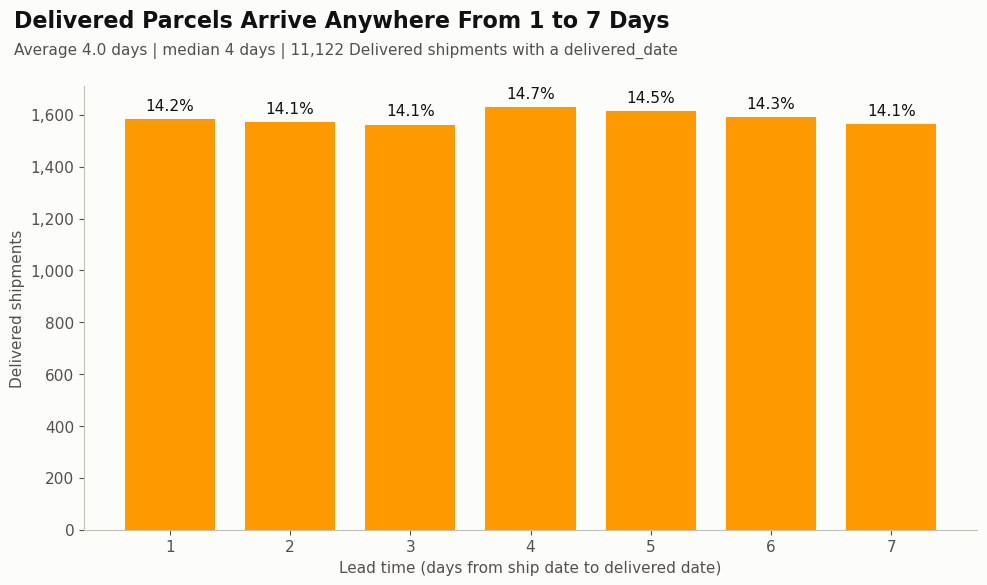

In [17]:
lead = fact.loc[fact["in_lead_time_scope"], "lead_time_days"]

fig, ax = plt.subplots()
counts, edges, bars = ax.hist(lead, bins = range(1, 9), align = "left", rwidth = 0.75, color = THEME["accent"])
ax.bar_label(bars, labels = [f"{c / len(lead):.1%}" for c in counts], padding = 4)

ax.set_xticks(range(1, 8))
ax.set_xlabel("Lead time (days from ship date to delivered date)")
ax.set_ylabel("Delivered shipments")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

finish_chart(
    fig, 
    title = "Delivered Parcels Arrive Anywhere From 1 to 7 Days",
    subtitle = f"Average {lead.mean():.1f} days | median {lead.median():.0f} days | "
                f"{len(lead):,} Delivered shipments with a delivered_date",
    file_name = "01_lead_time_distribution",
)

## PC18: Courier Comparison Chart
Plots average lead time and return rate by courier and saves it as 02_courier_comparison.png.

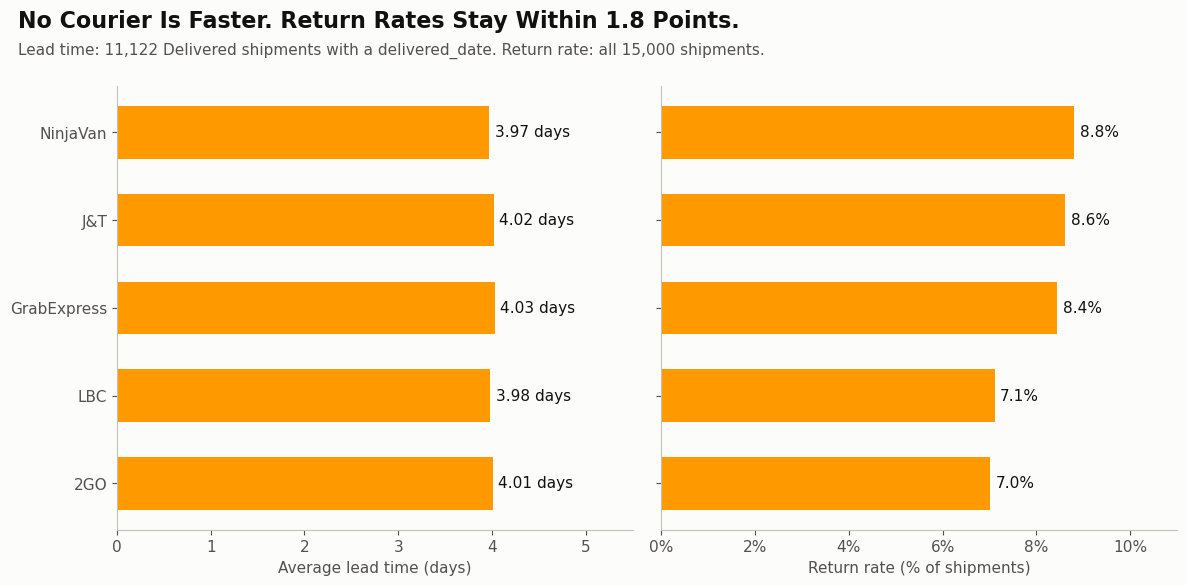

In [18]:
cs = courier_summary.sort_values("return_rate_pct")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 6), sharey = True)

bars1 = ax1.barh(cs.index, cs["avg_lead_time_days"], height = 0.6, color = THEME["accent"])
ax1.bar_label(bars1, fmt = "%.2f days", padding = 4)
ax1.set_xlim(0, 5.5)
ax1.set_xlabel("Average lead time (days)")

bars2 = ax2.barh(cs.index, cs["return_rate_pct"], height = 0.6, color = THEME["accent"])
ax2.bar_label(bars2, fmt = "%.1f%%", padding = 4)
ax2.set_xlim(0, 11)
ax2.set_xlabel("Return rate (% of shipments)")
ax2.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:.0f}%"))

finish_chart(
    fig, 
    title = "No Courier Is Faster. Return Rates Stay Within 1.8 Points.",
    subtitle = f"Lead time: {int(cs['delivered_n'].sum()):,} Delivered shipments with a delivered_date. "
                f"Return rate: all {int(cs["shipments"].sum()):,} shipments.", 
    file_name = "02_courier_comparison",
)

## PC19: Return Reasons
Plots the return reasons with delivery-related reasons highlighted and saves it as 03_return_reasons.png.

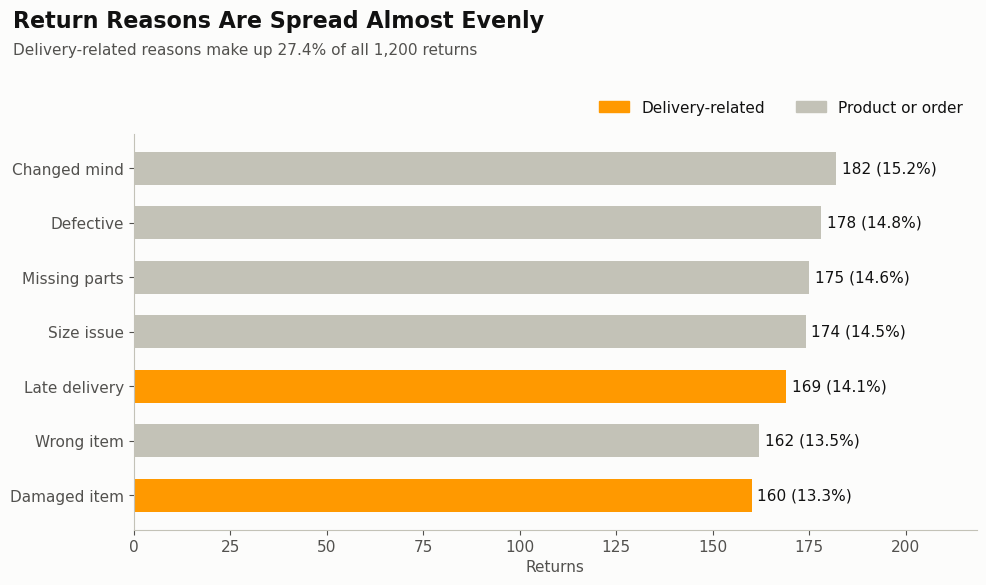

In [19]:
delivery_reasons = ["Late delivery", "Damaged item"]
reasons = reason_summary.sort_values("returns")
colors = [THEME["accent"] if r in delivery_reasons else THEME["muted"]for r in reasons.index]
delivery_share = reason_summary.loc[delivery_reasons, "returns"].sum() / len(rt)

fig, ax = plt.subplots()
bars = ax.barh(reasons.index, reasons["returns"], height = 0.6, color = colors)
ax.bar_label(bars, labels = [f"{n} ({p:.1f}%)" for n, p in zip(reasons["returns"], reasons["pct_of_returns"])],
            padding = 4)
ax.set_xlim(0, reasons["returns"].max() * 1.2)
ax.set_xlabel("Returns")
ax.legend(handles = [Patch(color = THEME["accent"], label = "Delivery-related"), 
                     Patch(color = THEME["muted"], label = "Product or order")], 
         loc = "upper right", bbox_to_anchor = (1, 1.12), ncol = 2, frameon = False)

finish_chart(
    fig, 
    title = "Return Reasons Are Spread Almost Evenly",
    subtitle = f"Delivery-related reasons make up {delivery_share:.1%} of all {len(rt):,} returns",
    file_name = "03_return_reasons",
)

## PC20: Return Rate by Category
Plots the return rate by product category and saves it as 04_return_rate_by_category.png.

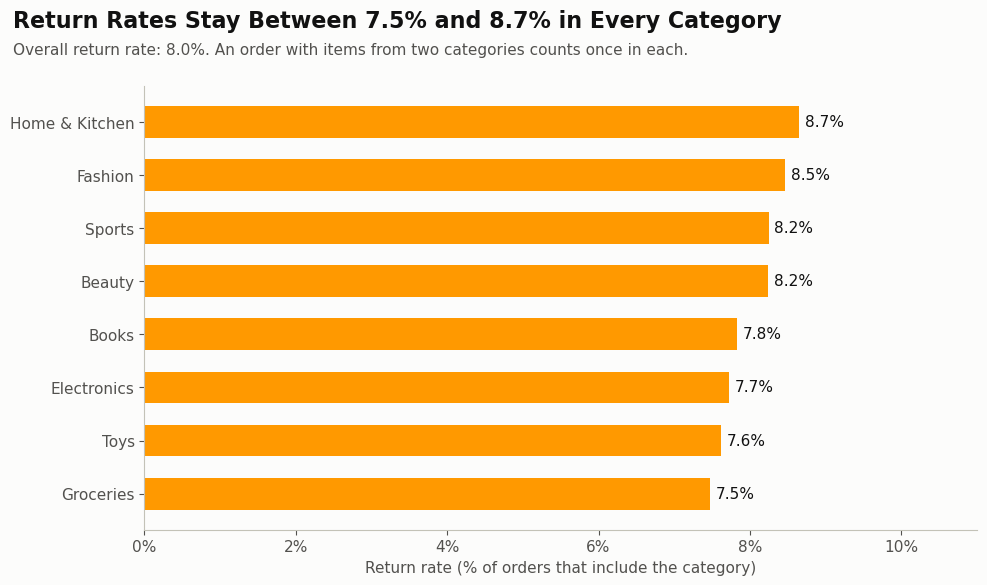

In [20]:
cat = category_summary.sort_values("return_rate_pct")

fig, ax = plt.subplots()
bars = ax.barh(cat.index, cat["return_rate_pct"], height = 0.6, color = THEME["accent"])
ax.bar_label(bars, fmt = "%.1f%%", padding = 4)
ax.set_xlim(0, 11)
ax.set_xlabel("Return rate (% of orders that include the category)")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:.0f}%"))

finish_chart(
    fig,
    title = f"Return Rates Stay Between {cat['return_rate_pct'].min():.1f}% and "
            f"{cat['return_rate_pct'].max():.1f}% in Every Category", 
    subtitle = f"Overall return rate: {return_rate:.1%}. An order with items from two categories counts once in each.",
    file_name = "04_return_rate_by_category",
)

## PC21: Shipment Status Breakdown
Plots the shipment status breakdown and saves it as 05_shipment_status_breakdown.png.

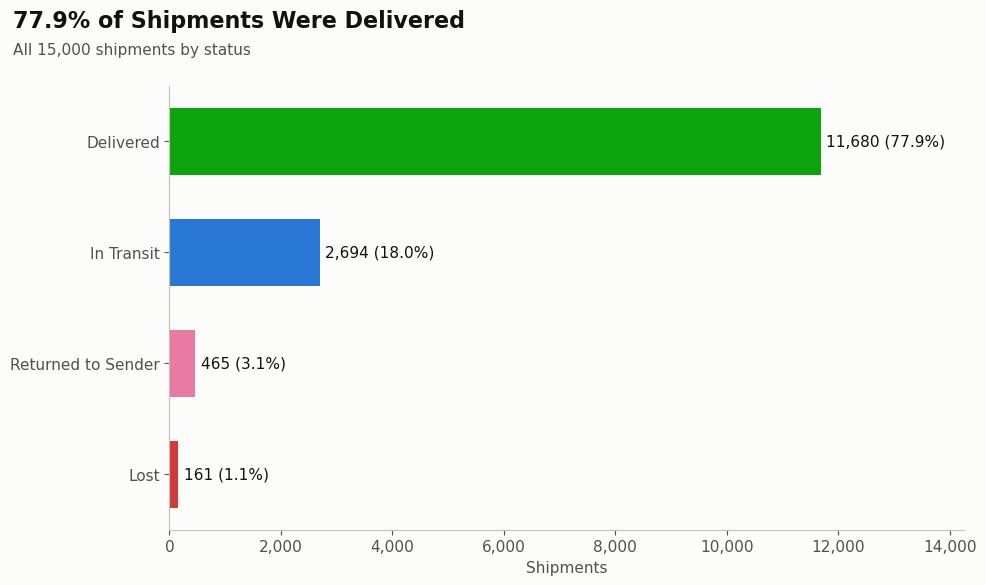

In [21]:
status_order = fact["shipment_status"].value_counts().index

fig, ax = plt.subplots()
sns.countplot(data = fact, y = "shipment_status", order = status_order, hue = "shipment_status",
             palette = STATUS_COLORS, legend = False, width = 0.6, saturation = 1, ax = ax)

for bars in ax.containers:
    ax.bar_label(bars, labels = [f"{n:,.0f} ({n / len(fact):.1%})" for n in bars.datavalues], padding = 4)
ax.set_xlim(0, len(fact) * 0.95)
ax.set_xlabel("Shipments")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

delivered_pct = fact["shipment_status"].eq("Delivered").mean()
finish_chart(
    fig, 
    title = f"{delivered_pct:.1%} of Shipments Were Delivered",
    subtitle = f"All {len(fact):,} shipments by status",
    file_name = "05_shipment_status_breakdown",
)

## PC22: Levene's Test for Equal Variances
Tests whether the spread of lead time is equal across couriers and shipping methods.

Question: Does any courier or shipping method deliver with a tighter spread of lead times? (Follows PC14 and PC17.)

In [22]:
from scipy import stats

delivered = fact[fact["in_lead_time_scope"]]
print(f"Lead time scope: {len(delivered)} Delivered shipments with a delivered_date\n")

levene_rows = []
for col in ["courier", "shipping_method"]:
    groups = [g["lead_time_days"] for _, g in delivered.groupby(col)]
    w_stat, p_value = stats.levene(*groups)
    std_dev = delivered.groupby(col)["lead_time_days"].std()
    levene_rows.append((
        col,
        len(groups),
        round(w_stat, 2),
        round(p_value, 3),
        f"{std_dev.min():.2f} to {std_dev.max():.2f}"
    ))

levene_summary = pd.DataFrame(levene_rows,
                             columns = ["group_by", "groups", "W", "p_value", "std_dev_days"])

levene_summary

Lead time scope: 11122 Delivered shipments with a delivered_date



,group_by,groups,W,p_value,std_dev_days
0,courier,5,1.56,0.182,1.97 to 2.03
1,shipping_method,3,0.17,0.846,1.99 to 2.00


## PC23: One-Way ANOVA (Tukey Only If Significant)
Tests whether average lead time differs by courier or by shipping method and adds R² and a Kruskal-Wallis check.

Question: Is any courier, or Express shipping, actually faster on average? (Follows PC14 and PC13.)

In [23]:
grand_mean = delivered["lead_time_days"].mean()
ss_total = ((delivered["lead_time_days"] - grand_mean) ** 2).sum()

anova_rows = []
for col in ["courier", "shipping_method"]:
    groups = [g["lead_time_days"] for _, g in delivered.groupby(col)]
    f_stat, p_value = stats.f_oneway(*groups)
    h_stat, kw_p = stats.kruskal(*groups)

    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    means = delivered.groupby(col)["lead_time_days"].mean()
    anova_rows.append((
        col,
        round(f_stat, 2),
        round(p_value, 3),
        round(ss_between / ss_total * 100, 3),
        f"{means.min():.2f} to {means.max():.2f}",
        round(kw_p, 3)
    ))

    if p_value < 0.05:
        print(f"{col}: significant, Tukey test below")
        print(stats.tukey_hsd(*groups))
    else: 
        print(f"{col}: p = {p_value:.3f}, not significant. No Tukey Test.")

anova_summary = pd.DataFrame(anova_rows, columns = ["group_by", "F", "p_value", "r_squared_pct", "mean_lead_time_days", "kruskal_wallis_p"])

anova_summary

courier: p = 0.841, not significant. No Tukey Test.
shipping_method: p = 0.661, not significant. No Tukey Test.


,group_by,F,p_value,r_squared_pct,mean_lead_time_days,kruskal_wallis_p
0,courier,0.35,0.841,0.013,3.97 to 4.03,0.842
1,shipping_method,0.41,0.661,0.007,3.98 to 4.02,0.659


## PC24: Chi-Square and Cramer's V
Tests whether shipment status, returns, and return reasons depend on the courier and measures the strength with Cramer's V.

Question: Do shipment status, returns, and return reasons depend on the courier? (Follows PC14, PC19, and PC21.)

In [24]:
def chi_square(table, name):
    """Chi-square test of independence plus Cramer's V for one crosstab."""
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    cramers_v = (chi2 / (n * (min(table.shape) - 1))) ** 0.5
    return (name, n, round(chi2, 2), dof, round(p_value, 3), round(cramers_v, 3), round(expected.min(), 1))

rt = clean["returns"]
return_courier = rt["order_id"].map(fact.set_index("order_id")["courier"])

chi_rows = [
    chi_square(pd.crosstab(fact["courier"], fact["shipment_status"]), "Shipment status x courier"),
    chi_square(pd.crosstab(fact["courier"], fact["has_return"]), "Returned x courier"),
    chi_square(pd.crosstab(return_courier, rt["reason"]), "Return reason x courier"),
]

chi_summary = pd.DataFrame(chi_rows, columns = ["test", "n", "chi2", "df", "p_value", "cramers_v", "min_expected"])

chi_summary

,test,n,chi2,df,p_value,cramers_v,min_expected
0,Shipment status x courier,15000,8.96,12,0.706,0.014,31.7
1,Returned x courier,15000,12.15,4,0.016,0.028,236.1
2,Return reason x courier,1200,23.43,24,0.494,0.070,27.6
